In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)


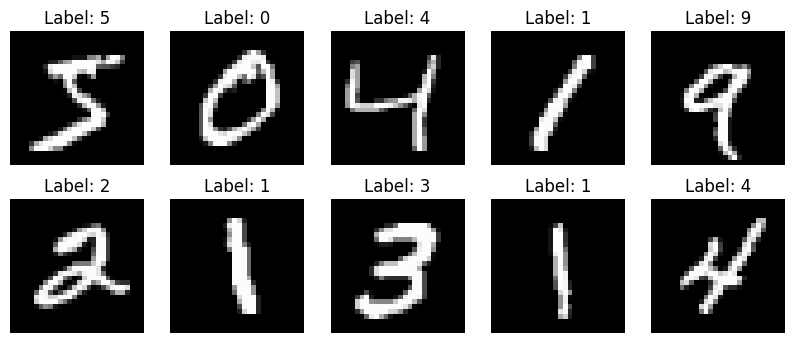

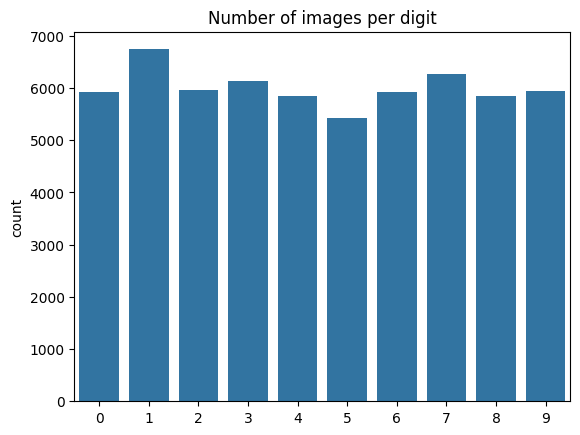

In [3]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.show()

sns.countplot(x=y_train)
plt.title("Number of images per digit")
plt.show()

In [4]:
# Scale pixel values from 0-255 to 0-1
X_train = X_train.astype("float32") / 255
X_test = X_test.astype("float32") / 255

# Add a channel dimension: (28, 28) -> (28, 28, 1)
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

print(X_train.shape, X_test.shape)

(60000, 28, 28, 1) (10000, 28, 28, 1)


In [5]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(X_train, y_train,
                    epochs=8,
                    batch_size=128,
                    validation_split=0.1)

Epoch 1/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 46s 97ms/step - accuracy: 0.9299 - loss: 0.2366 - val_accuracy: 0.9837 - val_loss: 0.0566
Epoch 2/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 89ms/step - accuracy: 0.9786 - loss: 0.0698 - val_accuracy: 0.9878 - val_loss: 0.0449
Epoch 3/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 90ms/step - accuracy: 0.9845 - loss: 0.0498 - val_accuracy: 0.9902 - val_loss: 0.0348
Epoch 4/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 89ms/step - accuracy: 0.9879 - loss: 0.0395 - val_accuracy: 0.9895 - val_loss: 0.0349
Epoch 5/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 37s 89ms/step - accuracy: 0.9892 - loss: 0.0339 - val_accuracy: 0.9913 - val_loss: 0.0329
Epoch 6/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 89ms/step - accuracy: 0.9909 - loss: 0.0279 - val_accuracy: 0.9905 - val_loss: 0.0339
Epoch 7/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 90ms/step - accuracy: 0.9922 - loss: 0.0243 - val_accuracy: 0.9902 - val_loss: 0.0337
Epoch 8/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 90ms/step - accuracy: 0.9933 - loss: 0.0208 - val_accu

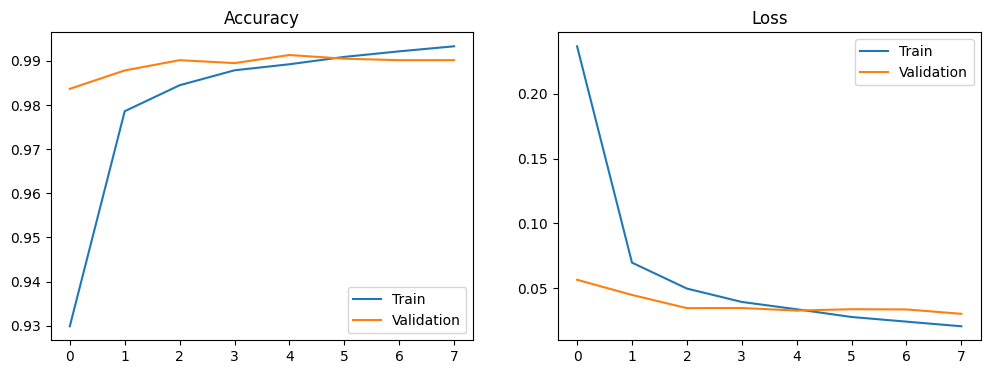

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy"); axes[0].legend()

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss"); axes[1].legend()
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

y_pred = np.argmax(model.predict(X_test), axis=1)
print(classification_report(y_test, y_pred))

Test accuracy: 0.9915
292/313 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

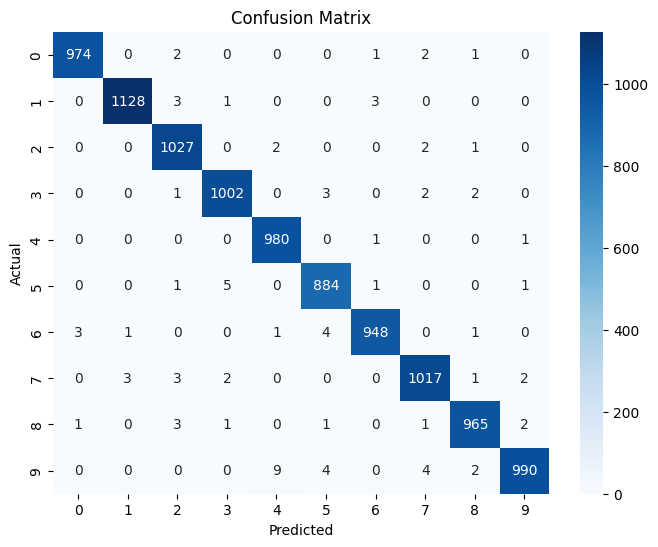

In [9]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

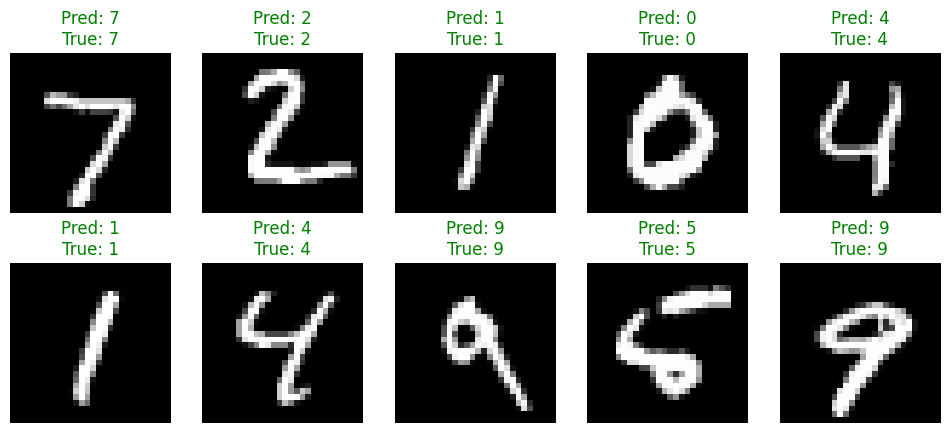

In [10]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")
    color = "green" if y_pred[i] == y_test[i] else "red"
    plt.title(f"Pred: {y_pred[i]}\nTrue: {y_test[i]}", color=color)
    plt.axis("off")
plt.show()

Total mistakes: 85


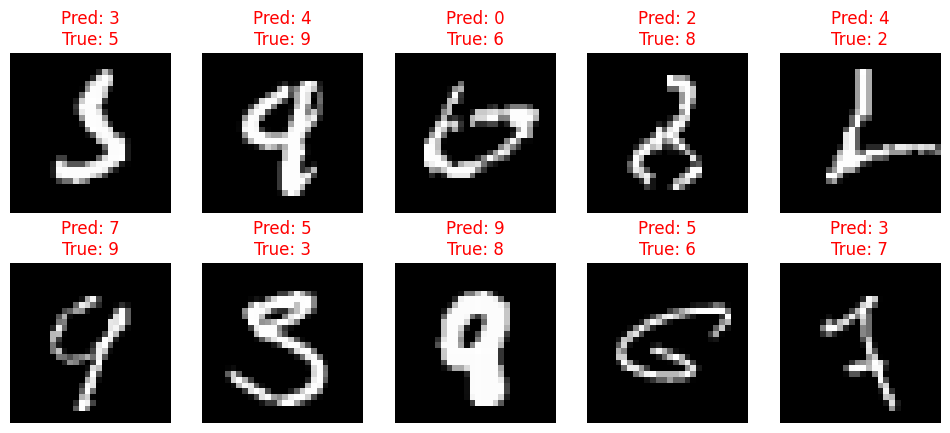

In [11]:
wrong = np.where(y_pred != y_test)[0]
print("Total mistakes:", len(wrong))

plt.figure(figsize=(12, 5))
for i, idx in enumerate(wrong[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(f"Pred: {y_pred[idx]}\nTrue: {y_test[idx]}", color="red")
    plt.axis("off")
plt.show()

## Conclusion

In this project I built a Convolutional Neural Network (CNN) that
recognizes handwritten digits (0-9) using the MNIST dataset (60,000
training images and 10,000 test images, each 28x28 grayscale pixels).

**Model:** Two Conv2D layers (32 and 64 filters) with MaxPooling, followed
by Flatten, Dropout (0.3), a Dense layer of 128 units and a softmax output
of 10 classes. Pixel values were scaled to 0-1, and the model was trained
for 8 epochs with the Adam optimizer, using 10% of the training data for
validation.

**Results:** The model reached a test accuracy of **99.15%**, making only
about 85 mistakes out of 10,000 images. The training and validation curves
stayed close together, which shows the model is not badly overfitting.

**Error analysis:** The confusion matrix and the misclassified images show
that most mistakes happen between digits that look alike, such as 4 and 9
and 3 and 5 . Many of these images are unclear or sloppily written, and
some are hard even for a human to read.

**Takeaway:** A small CNN can recognize handwritten digits with very high
accuracy because convolution layers learn useful patterns like edges and
curves on their own. Future improvements include data augmentation
(rotating or shifting images), a deeper network, and extending the model to
letters with the EMNIST dataset or to full words using a CRNN.